In [1]:
import datetime
import functools
import math
from typing import Callable

from line_profiler import profile
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import jax.scipy as jsp
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
import scipy as scp

%matplotlib inline
%load_ext line_profiler

In [2]:
df = pd.read_csv("sotonmet.txt", parse_dates=["Reading Date and Time (ISO)"])
t = df["Reading Date and Time (ISO)"]
t = (t - t.min()).dt.total_seconds() / 86400
t = t.to_numpy()
f = df["Tide height (m)"].to_numpy()
y = df["True tide height (m)"].to_numpy()
df.head()

,Update Date and Time (ISO),Update Duration (ms),Reading Date and Time (ISO),Air pressure (mb),Air temperature (C),Tide height (m),Wind direction (deg),Wind gust speed (kn),Wind speed (kn),True air temperature (C),True tide height (m),Independent tide height prediction (m),Independent tide height deviation (m),Dependent tide height prediction (m),Dependent tide height deviation (m),Independent air temperature prediction (C),Independent air temperature deviation (C),Dependent air temperature prediction (C),Dependent air temperature deviation (C)
0,2007-05-26T12:05:00,0,2007-05-26 12:05:00,NaN,NaN,NaN,NaN,NaN,NaN,16.92,2.30,2.4007,0.039110,2.3715,0.036670,17.2348,0.23222,17.2339,0.23187
1,2007-05-26T12:10:00,0,2007-05-26 12:10:00,1006.0,16.7,2.3,22.0,12.0,12.4,16.42,2.24,2.4016,0.058707,2.3365,0.045564,17.1932,0.29931,17.1848,0.29732
2,2007-05-26T12:15:00,0,2007-05-26 12:15:00,1006.0,16.0,2.2,13.0,18.1,13.2,16.00,2.19,2.2945,0.037006,2.2836,0.029853,16.8005,0.25186,16.8130,0.24920
3,2007-05-26T12:20:00,0,2007-05-26 12:20:00,1006.0,15.9,2.1,16.0,14.2,13.0,15.92,2.14,2.1455,0.021627,2.1553,0.019945,16.0734,0.17207,16.0621,0.17101
4,2007-05-26T12:25:00,0,2007-05-26 12:25:00,1005.0,16.1,2.1,12.0,14.4,12.0,16.08,2.09,2.0900,0.028609,2.1115,0.023468,15.8401,0.21507,15.8126,0.21158


In [3]:
mask = np.isfinite(f) & np.isfinite(t)

t_clean = t[mask]
f_clean = f[mask]

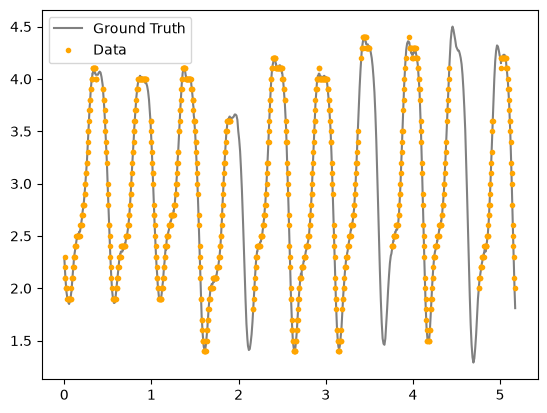

In [4]:
plt.plot(t, y, label="Ground Truth", color="grey")
plt.plot(t, f, '.', label="Data", color="Orange")
plt.legend()

In [5]:
def is_psd(A, tol=1e-10):
    return (
        jnp.allclose(A, A.T, atol=tol, rtol=0)
        and jnp.all(jnp.linalg.eigvalsh(A) >= -tol)
    )

In [6]:
def d(x1: jax.Array, x2: jax.Array) -> float:
    return jnp.abs(x1 - x2)

def k_rbf(l: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: l ** 2 * jnp.exp(
        -d(x1, x2) ** 2 / (2 * lengthscale ** 2)
        )

def k_rational_quadratic(l: float, alpha: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: l ** 2 * (1 + d(x1, x2) ** 2 / 2 / alpha / lengthscale ** 2) ** -alpha

def k_periodic(l: float, rho: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: l ** 2 * jnp.exp(-2 * jnp.sin(jnp.pi * d(x1, x2) / rho) ** 2 / lengthscale ** 2)

def k_sum(k1: Callable[[jax.Array, jax.Array], float], k2: Callable[[jax.Array, jax.Array], float]) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: k1(x1, x2) + k2(x1, x2)

def k_multiply(k1: Callable[[jax.Array, jax.Array], float], k2: Callable[[jax.Array, jax.Array], float]) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: k1(x1, x2) * k2(x1, x2) 

In [7]:
def mu_zero() -> Callable[[jax.Array], jax.Array]:
    return lambda x: jnp.zeros_like(x)

def mu_mean(f: jax.Array) -> Callable[[jax.Array], jax.Array]:
    return mu_constant(jnp.mean(f))

def mu_constant(theta: float) -> Callable[[jax.Array], jax.Array]:
    return lambda x: jnp.full_like(x, theta)

In [8]:
class GaussianProcess:
    def __init__(
        self,
        t: jax.Array,
        f: jax.Array,
        mean_func: Callable[[jax.Array], jax.Array],
        kernel: Callable[[jax.Array, jax.Array], float],
        noise_std: float = 0.1
    ):
        self._t = t
        self._f = f
        self._mean_func = mean_func
        self._kernel = kernel
        self.noise_std = noise_std
        self.K = self._compute_K(t, t, kernel)
        self.K += noise_std**2 * jnp.eye(len(t))
        self.residual = f - mean_func(t)

        self.cho = jsp.linalg.cho_factor(self.K, lower=True)
        self.alpha = jsp.linalg.cho_solve(self.cho, self.residual)
        self._cholesky_cache = dict()
    
    def predict(self, t: jax.Array) -> tuple[jax.Array, jax.Array]:
        K_new = self._compute_K(t, self._t, self._kernel)
        K_ss = self._compute_K(t, t, self._kernel)

        m = self._mean_func(t) + K_new @ self.alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve(self.cho, K_new.T)
        C = (C + C.T) / 2

        return m, C

    def predict_sequential(self, t: float) -> tuple[jax.Array, jax.Array]:
        i = int(jnp.count_nonzero(self._t <= t)) - 1
        t_causal = self._t[:i+1]
        f_causal = self._f[:i+1]
        L = self._cholesky_for_index(i)
        t = jnp.atleast_1d(t)
        residual = f_causal - self._mean_func(t_causal)
        alpha = jsp.linalg.cho_solve((L, True), residual)

        K_new = self._compute_K(t, t_causal, self._kernel)
        K_ss = self._kernel(t, t)

        m = self._mean_func(t) + K_new @ alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve((L, True), K_new.T)  
        C = (C + C.T) / 2
        
        return m, C
    
    def predict_sequential_sliding_window(self, t: float, lookahead: float = 0) -> tuple[jax.Array, jax.Array]:
        window = 1 # 1 day sliding window - hardcoded for now...

        n = int(jnp.searchsorted(self._t, t - lookahead, 'left'))
        m = int(jnp.searchsorted(self._t, t - window - lookahead, 'left'))
        t_causal = self._t[m:n]
        f_causal = self._f[m:n]

        K = self.K[m:n, m:n]
        L = jnp.linalg.cholesky(K)
        t = jnp.atleast_1d(t)
        residual = f_causal - self._mean_func(t_causal)
        alpha = jsp.linalg.cho_solve((L, True), residual)

        K_new = self._compute_K(t, t_causal, self._kernel)
        K_ss = self._kernel(t, t)

        m = self._mean_func(t) + K_new @ alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve((L, True), K_new.T)  
        C = (C + C.T) / 2
        
        return m, C

    @functools.cache
    def _cholesky_for_index(self, i: int) -> jax.Array:
        if i <= 5:
            # for small i, compute directly
            t = self._t[:i+1]
            K = self.K[:i+1, :i+1]
            K += self.noise_std**2 * jnp.eye(len(t))
            return jsp.linalg.cho_factor(K, lower=True)[0]
        
        prev_L = self._cholesky_for_index(i-1)
        t_old = self._t[:i]
        t_new = self._t[i]
        return self.update_cholesky(prev_L, t_old, t_new)

    def update_cholesky(self, L: jax.Array, t_old: jax.Array, t_new: float) -> jax.Array:
        """
        Update the Cholesky factor after adding one observation.

        Parameters
        ----------
        L : (n, n) array
            Lower triangular Cholesky factor of the
            existing noisy covariance matrix.

        t_old : (n,) array
            Existing training input locations.

        t_new : float
            Input location of the new observation.

        Returns
        -------
        L_new : (n+1, n+1) array
            Updated lower triangular Cholesky factor.
        """

        t_new = jnp.atleast_1d(t_new)
        n = len(t_old)

        # Covariance between new and existing inputs
        k = self.K[:n, n]

        # Variance of new noisy observation
        c = self.K[n, n] + self.noise_std**2

        # Solve L @ v = k
        v = jsp.linalg.solve_triangular(
            L, k, lower=True
        )

        # New diagonal entry
        d = jnp.sqrt(c - v @ v)

        L_new = jnp.zeros((n + 1, n + 1))
        L_new = L_new.at[:n, :n].set(L)
        L_new = L_new.at[n, :n].set(v)
        L_new = L_new.at[n, n].set(d)

        return L_new

    def log_likelihood(self):
        N = len(self._t)

        return (
            -0.5 * self.residual @ self.alpha
            - jnp.sum(jnp.log(jnp.diag(self.cho[0])))
            - 0.5 * N * jnp.log(2 * np.pi)
        )

    def predictive_log_likelihood(self, t_test: jax.Array, y_test: jax.Array):
        if len(t_test) != len(y_test):
            raise ValueError("t_test and y_test should have the same length")

        n = len(y_test)
        m, C = self.predict(t_test)

        # Include observation noise
        C_y = C + self.noise_std**2 * jnp.eye(n)

        L, _ = jsp.linalg.cho_factor(C_y, True)
        residual = y_test - m

        alpha = jsp.linalg.cho_solve(
            (L, True), residual
        )

        return (
            -0.5 * residual @ alpha
            - jnp.sum(jnp.log(jnp.diag(L)))
            - 0.5 * n * jnp.log(2 * jnp.pi)
        )

    @staticmethod
    def _compute_K(t1, t2, kernel):
        t1 = jnp.asarray(t1)
        t2 = jnp.asarray(t2)

        return kernel(t1[:, None], t2[None, :])

    

In [ ]:

# k = k_rbf(3, 0.5)
k = k_periodic(
    l=3,
    rho=12.42 / 24,
    lengthscale=0.5
)
GP_zeromean_periodic = GaussianProcess(t_clean, f_clean, mu_zero(), k)

In [10]:
def evaluate(gp: GaussianProcess):
    m, C = gp.predict(t)
    std = jnp.sqrt(jnp.diag(C))

    rmse = jnp.linalg.norm(y - m) / math.sqrt(len(y))
    print(f"RMSE = {rmse}")
    predictive_log_likelihood = gp.predictive_log_likelihood(t, y)
    print(f"Predictive Log Likelihood = {predictive_log_likelihood}")

    # Plot predicted mean
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.20052635940005978
Predictive Log Likelihood = -754.3123182904287


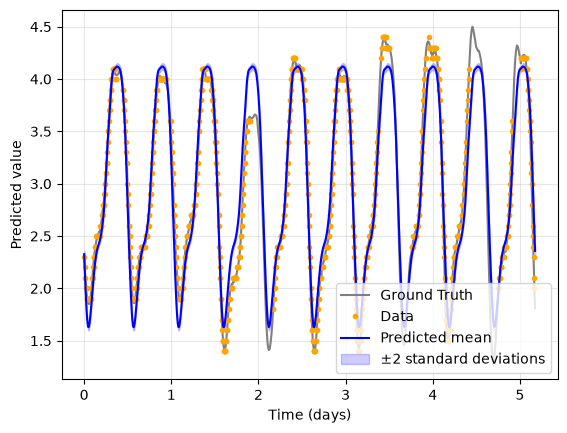

In [ ]:
evaluate(GP_zeromean_periodic)

## Maximum likelihood estimation of GP parameters

In [12]:
def loss_mle(
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]]
    ) -> Callable[[jax.Array], float]:
    return lambda hypers: -GaussianProcess(t_clean, f_clean, mu_factory(hypers), k_factory(hypers)).log_likelihood()


In [13]:
def optimise_hypers(loss_fun: Callable, mu_factory: Callable, k_factory: Callable) -> jax.Array:
    loss_and_grad = jax.jit(jax.value_and_grad(loss_fun(mu_factory, k_factory)))
    result = scp.optimize.minimize(loss_and_grad, [0, 1, 1, 12.42 / 24, 1], method="L-BFGS-B", jac=True, bounds=[
        (None, None),
        (0.001, None),
        (0.001, None),
        (0.001, None),
        (0.001, None),
    ])
    best_hypers = result.x
    print(best_hypers)
    return best_hypers

In [14]:
mu_factory = lambda hypers: mu_constant(hypers[0])
k_factory = lambda hypers: k_multiply(k_rbf(hypers[1], hypers[2]), k_periodic(hypers[1], hypers[3], hypers[4]))
best_mle_hypers = optimise_hypers(loss_mle, mu_factory, k_factory)
gp_mle = GaussianProcess(t_clean, f_clean, mu_factory(best_mle_hypers), k_factory(best_mle_hypers))

[2.93479181 0.95106188 0.61092544 0.51835291 1.05551975]


RMSE = 0.031373867972965874
Predictive Log Likelihood = 1667.2468534442992


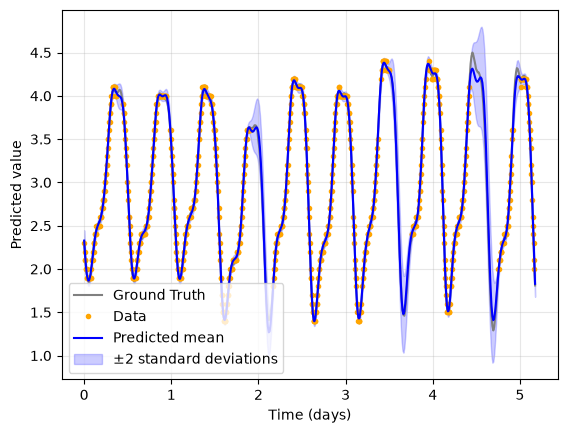

In [15]:
evaluate(gp_mle)

## Maximum a posteriori estimation of GP parameters

In [16]:
def loss_map(
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]],
    prior_func: Callable[[jax.Array], float]
    ) -> Callable[[jax.Array], float]:
    return lambda hypers: -GaussianProcess(t_clean, f_clean, mu_factory(hypers), k_factory(hypers)).log_likelihood() - prior_func(hypers)

In [17]:
def hyper_prior(hypers: jax.Array) -> float:
    mu, l, lengthscale_rbf, rho, lengthscale_periodic = hypers
    return (
        jsp.stats.norm.logpdf(mu, 3, 2) +
        jsp.stats.norm.logpdf(l, 3, 2) +
        jsp.stats.norm.logpdf(lengthscale_rbf, 2, 2) +
        jsp.stats.norm.logpdf(rho, 1, 1) +
        jsp.stats.norm.logpdf(lengthscale_periodic, 2, 2)
    )


best_map_hypers = optimise_hypers(lambda x, y: loss_map(x, y, hyper_prior), mu_factory, k_factory)
gp_map = GaussianProcess(t_clean, f_clean, mu_factory(best_map_hypers), k_factory(best_map_hypers))

[2.93584976 0.95514274 0.61208562 0.51835452 1.05983282]


RMSE = 0.031423059702946246
Predictive Log Likelihood = 1667.2133876354123


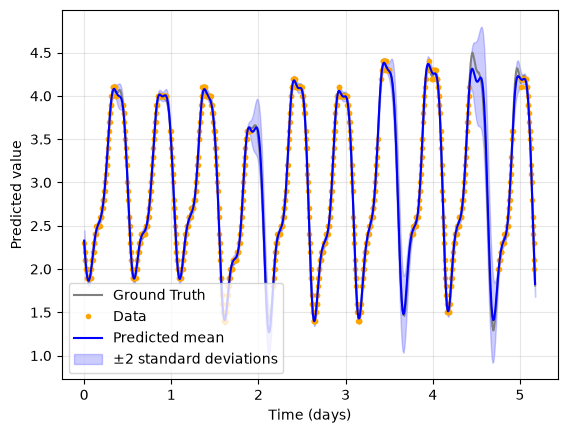

In [18]:
evaluate(gp_map)

## Sequential Prediction of Data

In [19]:
def evaluate_sequential(gp: GaussianProcess):
    n = 100 # runs slowly for n too high, even with optimisations...
    results = [gp.predict_sequential(float(x)) for x in t[:n]]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])

    rmse = jnp.linalg.norm(y[:n] - m) / math.sqrt(n)
    print(f"RMSE = {rmse}")

    # Plot predicted mean
    plt.plot(t[:n], y[:n], label="Ground Truth", color="grey")
    plt.plot(t[:n], f[:n], '.', label="Data", color="Orange")
    plt.plot(t[:n], m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t[:n],
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.07257037817064552


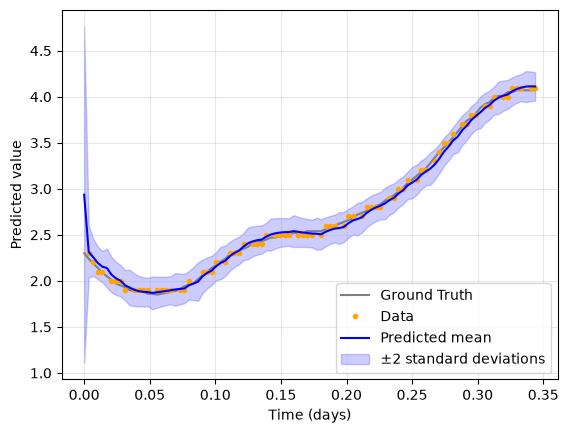

In [20]:
evaluate_sequential(gp_map)

In [21]:
def evaluate_sequential_sliding_window(gp: GaussianProcess):
    results = [gp.predict_sequential_sliding_window(float(x)) for x in t]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])

    rmse = jnp.linalg.norm(y - m) / math.sqrt(len(y))
    print(f"RMSE = {rmse}")

    # Plot predicted mean
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.12185162113635681


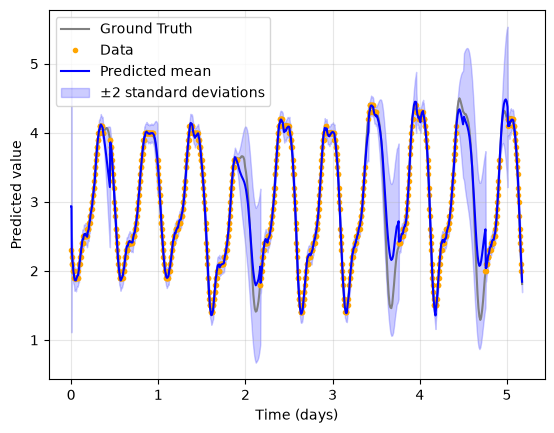

In [22]:
evaluate_sequential_sliding_window(gp_map)

## Lookahead

In [23]:
def format_timedelta(td):
    seconds = td.total_seconds()
    if seconds >= 86400:
        return f"{seconds / 86400:g} days"
    if seconds >= 3600:
        return f"{seconds / 3600:g} hours"
    if seconds >= 60:
        return f"{seconds / 60:g} mins"
    return f"{seconds:g} secs"

def evaluate_sequential_sliding_window_lookahead(gp: GaussianProcess, lookahead_td: datetime.timedelta):
    lookahead = lookahead_td.total_seconds() / 86400
    t_test = jnp.linspace(t.min(), t.max() + lookahead, 1000)
    results = [gp.predict_sequential_sliding_window(float(x), lookahead) for x in t_test]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])

    # Plot predicted mean
    plt.figure()
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t_test, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t_test,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel(f"Predicted value")
    plt.title(f"{format_timedelta(lookahead_td)} lookahead")
    plt.legend()
    plt.grid(alpha=0.3)

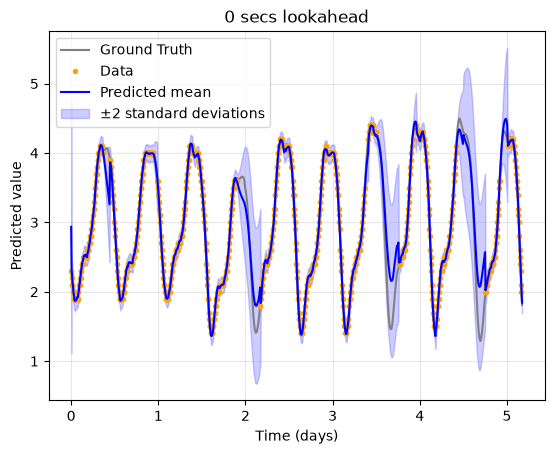

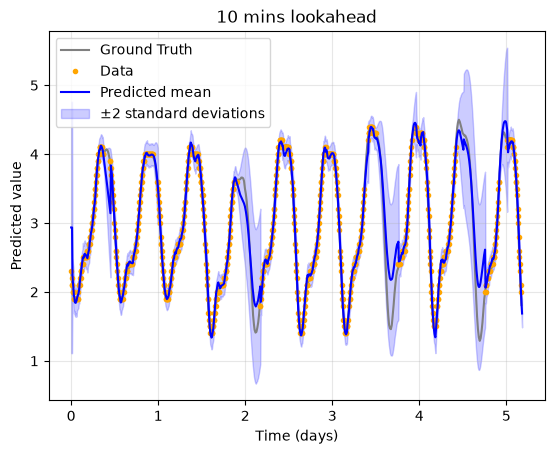

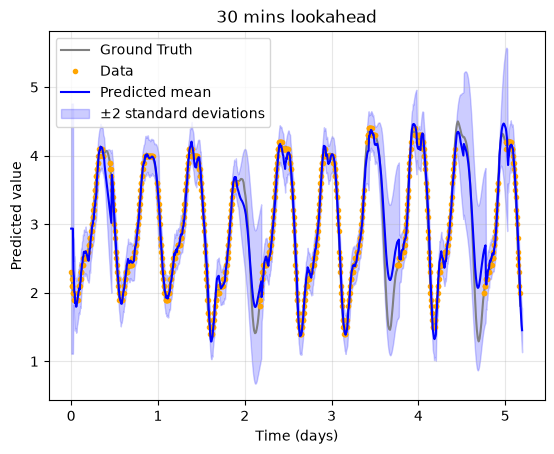

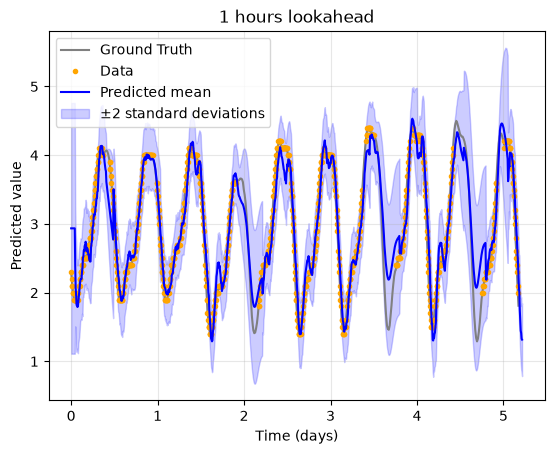

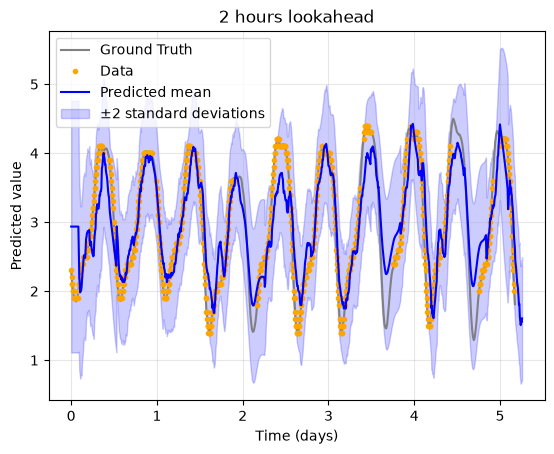

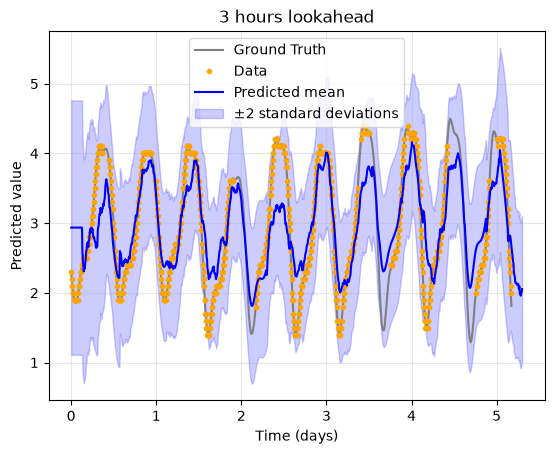

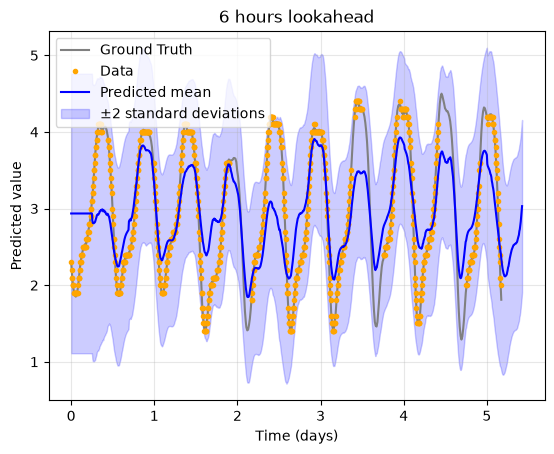

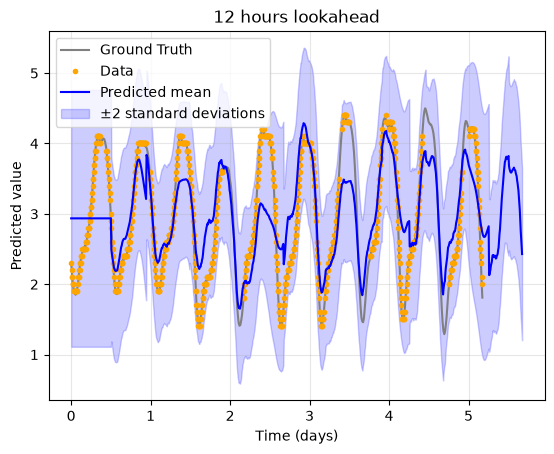

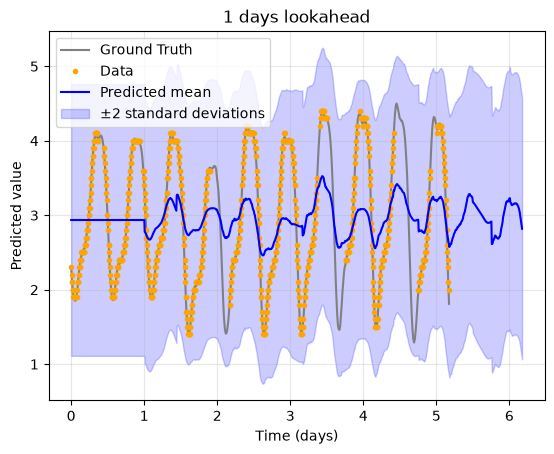

In [24]:
for lookahead in [datetime.timedelta(), datetime.timedelta(minutes=10), datetime.timedelta(minutes=30), datetime.timedelta(hours=1), datetime.timedelta(hours=2), datetime.timedelta(hours=3), datetime.timedelta(hours=6), datetime.timedelta(hours=12), datetime.timedelta(days=1)]:
    evaluate_sequential_sliding_window_lookahead(gp_map, lookahead)